<a href="https://colab.research.google.com/github/veorte/registros/blob/main/Actividad4EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 4**
Exploración de datos

---

*   NOMBRE: Verónica Ortega López
*   MATRÍCULA: A01841596

En esta actividad trabajarás con el archivo `personal_loan.csv`, basado en un conjunto de datos sobre clientes bancarios y su comportamiento financiero disponible en Kaggle.

Los datos fueron recopilados para analizar la posibilidad de que los clientes acepten un préstamo personal y contienen información demográfica, financiera y de productos bancarios asociados. Los indicadores incluidos son:

* `ID`: Identificador único del cliente
* `Age`: Edad del cliente (años completos)
* `Experience`: Experiencia laboral en años
* `Income`: Ingreso anual del cliente (en miles de dólares. Por ejemplo, 60 = 60,000 USD/año)
* `ZIP Code`: Código postal del cliente
* `Family`: Número de miembros de la familia
* `CCAvg`: Promedio de gastos mensuales con tarjeta de crédito (en miles de dólares)
* `Education`: Nivel educativo (1 = graduado, 2 = universitario, 3 = posgrado)
* `Mortgage`: Monto de hipoteca que posee el cliente (en miles de dólares)
* `Securities Account`: Indicador de si tiene cuenta de valores (1 = sí, 0 = no)
* `CD Account`: Indicador de si tiene cuenta de certificado de depósito (1 = sí, 0 = no)
* `Online`: Indicador de si usa los servicios bancarios en línea (1 = sí, 0 = no)
* `CreditCard`: Indicador de si es titular de tarjeta de crédito (1 = sí, 0 = no)
* `Personal Loan`: Si el cliente aceptó (1) o no (0) un préstamo personal. Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [27]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [28]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

1. Descarga el archivo: `personal_loan.csv` y guarda, en un dataframe (`loan_df`), todos sus registros.
* Haz que la columna `ID` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?

# Limpieza

In [29]:
loan_df = pd.read_csv("/content/drive/MyDrive/2. MNA Tec/Ciencia Analitica TC5053.10/Materiales para Tareas/Actividad4EDA/personal_loan.csv", index_col="ID")

In [30]:
loan_df.head()

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
0,25,1,49,91108,4,1.6,1.0,0,0,Yes,No,0,0
1,45,19,34,90089,3,1.5,1.0,0,No,Yes,No,No,0
2,39,15,11,94720,1,1.0,1.0,0,0,0,0,0,0
3,35,9,100,94112,1,2.7,2.0,0,0,0,0,No,0
4,35,8,45,91330,4,1.0,2.0,0,0,No,No,0,1


In [31]:
loan_df.shape

(5037, 13)

In [32]:
loan_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5037 entries, 0 to 5036
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 5037 non-null   int64  
 1   Experience          5037 non-null   int64  
 2   Income              5037 non-null   int64  
 3   ZIP Code            5037 non-null   int64  
 4   Family              5037 non-null   int64  
 5   CCAvg               5037 non-null   float64
 6   Education           5037 non-null   float64
 7   Mortgage            5037 non-null   int64  
 8   Personal Loan       5037 non-null   object 
 9   Securities Account  5037 non-null   object 
 10  CD Account          5037 non-null   object 
 11  Online              5037 non-null   object 
 12  CreditCard          5037 non-null   object 
dtypes: float64(2), int64(6), object(5)
memory usage: 550.9+ KB


In [33]:
print("Columnas numéricas:",
      len(loan_df.select_dtypes(include="number").columns))

print("Columnas de texto:",
      len(loan_df.select_dtypes(include="object").columns))

Columnas numéricas: 8
Columnas de texto: 5



¿Cuántas columnas son numéricas y cuántas de texto?
El dataframe contiene 8 columnas numéricas y 5 columnas de texto
---



2. Obtén las estadísticas descriptivas de las variables numéricas y examina cuidadosamente los valores obtenidos de cada columna.
* Filtra el dataframe para visualizar los registros en que la edad supera los 100 años y elimínalos si no son pausibles.
* Analiza el resto de las variables y elimina aquellos registros que contengan valores inválidos o inconsistentes. Para cada acción que realices, justifica la decisión, explicando por qué consideras que el valor es incorrecto.
* ¿Cuántos registros se eliminaron (considerando todas las acciones de este ejercicio) y qué porcentaje representa respecto al total del dataframe inicial?

In [34]:
loan_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,5037.0,45.411356,11.646805,23.0,35.0,45.0,55.0,144.0
Experience,5037.0,20.122494,11.461278,-3.0,10.0,20.0,30.0,43.0
Income,5037.0,73.898352,46.130504,8.0,39.0,64.0,98.0,224.0
ZIP Code,5037.0,93152.865595,2119.637960,9307.0,91911.0,93437.0,94608.0,96651.0
Family,5037.0,2.394679,1.151145,-3.0,1.0,2.0,3.0,4.0
CCAvg,5037.0,1.942404,1.755954,0.0,0.7,1.5,2.6,10.0
Education,5037.0,1.880941,0.843337,1.0,1.0,2.0,3.0,7.3
Mortgage,5037.0,56.500695,101.657580,0.0,0.0,0.0,101.0,635.0


In [35]:
loan_df[loan_df["Age"] > 100]

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
10,123,39,105,94710,4,2.4,3.0,0,0,0,0,No,0
250,144,6,29,94305,3,1.0,2.0,117,0,No,0,No,No
4800,130,7,73,94028,1,2.5,1.0,135,0,No,0,0,0


In [36]:
registros_iniciales = len(loan_df)

loan_df = loan_df[loan_df["Age"] <= 100].copy()

In [37]:
print("Experiencia negativa:",
      (loan_df["Experience"] < 0).sum())

print("Familia fuera de rango:",
      (~loan_df["Family"].between(1, 4)).sum())

print("Educación inválida:",
      (~loan_df["Education"].isin([1, 2, 3])).sum())

print("Ingreso negativo:",
      (loan_df["Income"] < 0).sum())

print("Gasto de tarjeta negativo:",
      (loan_df["CCAvg"] < 0).sum())

print("Hipoteca negativa:",
      (loan_df["Mortgage"] < 0).sum())

Experiencia negativa: 53
Familia fuera de rango: 2
Educación inválida: 1
Ingreso negativo: 0
Gasto de tarjeta negativo: 0
Hipoteca negativa: 0



Criterios de limpieza de la base de datos
*   Age:  3 edades mayores a 100 años
*   Experience:  No puede haber años de experiencia negativos
*   Family: 2 valores negativos, no se puede tener un número negativo de familiares
* Education: Un valor inválido



In [38]:
loan_df = loan_df[
    (loan_df["Experience"] >= 0) &
    (loan_df["Family"].between(1, 4)) &
    (loan_df["Education"].isin([1, 2, 3])) &
    (loan_df["Income"] >= 0) &
    (loan_df["CCAvg"] >= 0) &
    (loan_df["Mortgage"] >= 0)
].copy()

In [39]:
print("Registros eliminados hasta ahora:",
      registros_iniciales - len(loan_df))

Registros eliminados hasta ahora: 59


3. Obtén las estadísticas descriptivas de las variables de texto e imprime las frecuencias de sus categorías.
* Algunas columnas almacenan valores binarios utilizando distintos formatos. Unifica estos valores de manera consistente, asegurándote de que coincidan con la descripción de las variables al inicio de esta libreta.

In [40]:
loan_df.describe(include="object").T

,count,unique,top,freq
Personal Loan,4978,4,0,3475
Securities Account,4978,4,No,2693
CD Account,4978,4,No,2462
Online,4978,4,Yes,1700
CreditCard,4978,4,0,2628


In [43]:
# Obtener las frecuencias de todas las variables de texto:

text_cols = loan_df.select_dtypes(include="object").columns

for col in text_cols:
    print(f"\nVariable: {col}")
    print(loan_df[col].value_counts(dropna=False))


Variable: Personal Loan
Personal Loan
0      3475
No     1018
Yes     368
1       117
Name: count, dtype: int64

Variable: Securities Account
Securities Account
No     2693
0      1766
Yes     390
1       129
Name: count, dtype: int64

Variable: CD Account
CD Account
No     2462
0      2213
1       163
Yes     140
Name: count, dtype: int64

Variable: Online
Online
Yes    1700
No     1628
1      1276
0       374
Name: count, dtype: int64

Variable: CreditCard
CreditCard
0      2628
Yes     908
No      885
1       557
Name: count, dtype: int64


In [44]:
# Convertir las variables binarias en valores estandarizados de 0 y 1

binary_cols = [
    "Personal Loan",
    "Securities Account",
    "CD Account",
    "Online",
    "CreditCard"
]

binary_map = {
    "0": 0,
    "1": 1,
    "No": 0,
    "Yes": 1
}

for col in binary_cols:
    loan_df[col] = (
        loan_df[col]
        .astype(str)
        .str.strip()
        .map(binary_map)
    )

In [45]:
# Comprobación del resultado

for col in binary_cols:
    print(col)
    print(loan_df[col].value_counts(dropna=False))

Personal Loan
Personal Loan
0    4493
1     485
Name: count, dtype: int64
Securities Account
Securities Account
0    4459
1     519
Name: count, dtype: int64
CD Account
CD Account
0    4675
1     303
Name: count, dtype: int64
Online
Online
1    2976
0    2002
Name: count, dtype: int64
CreditCard
CreditCard
0    3513
1    1465
Name: count, dtype: int64


In [46]:
# Verificar que no haya valores nulos por algun error en la conversión

print(loan_df[binary_cols].isna().sum())

Personal Loan         0
Securities Account    0
CD Account            0
Online                0
CreditCard            0
dtype: int64


4. Verifica si hay registros duplicados y si fuera así, elimínalos del dataframe.
* Asegúrate de reiniciar el índice para mantener una secuencia continua tras todas las eliminaciones de registros que hasta este punto se han realizado.

In [47]:
# Buscar registros duplicados

loan_df.duplicated().sum()

np.int64(36)

In [48]:
# Inspección para asegurar que todos los registros son efectivamente errores

duplicados = loan_df[
    loan_df.duplicated(keep=False)
]

duplicados.sort_values(
    by=["Age", "Income"]
).head(20)

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
1160,28,1,40,95134,1,2.0,2.0,0,0,1,0,1,0
5031,28,1,40,95134,1,2.0,2.0,0,0,1,0,1,0
3673,34,9,65,95134,4,1.3,1.0,0,0,0,0,0,1
5032,34,9,65,95134,4,1.3,1.0,0,0,0,0,0,1
1202,35,11,24,95521,4,0.4,2.0,0,0,0,0,0,0
5005,35,11,24,95521,4,0.4,2.0,0,0,0,0,0,0
2101,35,5,203,95032,1,10.0,3.0,0,1,0,0,0,0
5020,35,5,203,95032,1,10.0,3.0,0,1,0,0,0,0
4641,36,11,31,94022,4,1.7,1.0,124,0,0,0,1,1


In [49]:
# Al comprobar que efectivamente son registros duplicados, se procede a eliminarlos conservando la primera aparición de cada registro

loan_df = loan_df.drop_duplicates().copy()

In [50]:
# Reiniciar el indice para conservar una secuencia sin saltos

loan_df = loan_df.reset_index(drop=True)
loan_df.index.name = "ID"

In [51]:
loan_df.head()
loan_df.shape

(4942, 13)

In [52]:
# Calculo del total de registros eliminados

registros_finales = len(loan_df)

eliminados = registros_iniciales - registros_finales

porcentaje = (
    eliminados / registros_iniciales
) * 100

print("Registros iniciales:", registros_iniciales)
print("Registros finales:", registros_finales)
print("Registros eliminados:", eliminados)
print(f"Porcentaje eliminado: {porcentaje:.2f}%")

Registros iniciales: 5037
Registros finales: 4942
Registros eliminados: 95
Porcentaje eliminado: 1.89%


5. Aunque hasta ahora se han considerado los tipos de datos inferidos por pandas, antes del EDA es recomendable revisar la naturaleza estadística de cada variable (continua, discreta, categórica, binaria, etc.) para aplicar el análisis adecuado.

* Efectúa las siguientes conversiones:
  - Nominal: ZIP Code - `object`
  - Ordinal: Education - `category` con orden 1, 2, 3
  - Binarias: Personal Loan, Securities Account, CD Account, Online, CreditCard - `category`
* Crea dos listas llamadas `num_cols` y `cat_cols` que contengan los nombres de las variables numéricas (int64, float64) y categóricas (object, category) del dataset, respectivamente.

In [54]:
# Convertir el ZIP Code a object (texto).  Usamos str.zfill(5) para agregar ceros a la izquierda ya que los códigos postales son identificadores y no valores de cantidad.

loan_df["ZIP Code"] = (
    loan_df["ZIP Code"]
    .astype(str)
    .str.zfill(5)
)

In [55]:
# Convertir Education a categoría ordinal

education_type = pd.CategoricalDtype(
    categories=[1, 2, 3],
    ordered=True
)

loan_df["Education"] = (
    loan_df["Education"].astype(education_type)
)

In [56]:
# Convertir las variables binarias

for col in binary_cols:
    loan_df[col] = loan_df[col].astype("category")

In [57]:
# Crear las listas num_cols y cat_cols

num_cols = loan_df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

cat_cols = loan_df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Variables numéricas:", num_cols)
print("Variables categóricas:", cat_cols)

Variables numéricas: ['Age', 'Experience', 'Income', 'Family', 'CCAvg', 'Mortgage']
Variables categóricas: ['ZIP Code', 'Education', 'Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']


# Análisis exploratorio de datos (univariado)

6. Para el análisis de las variables numéricas obtén nuevamente las estadísticas descriptivas incluyendo los valores de simetría y curtosis.
* Clasifica las variables `Age`, `Income` y `Mortgage` según los valores observados de asimetría y curtosis.

In [58]:
estadisticas = loan_df[num_cols].describe().T

estadisticas["Asimetría"] = loan_df[num_cols].skew()
estadisticas["Curtosis"] = loan_df[num_cols].kurt()

display(estadisticas.round(3))

,count,mean,std,min,25%,50%,75%,max,Asimetría,Curtosis
Age,4942.0,45.561,11.315,24.0,36.0,46.0,55.0,67.0,-0.023,-1.161
Experience,4942.0,20.336,11.307,0.0,11.0,20.0,30.0,43.0,-0.015,-1.135
Income,4942.0,73.816,46.108,8.0,39.0,64.0,98.0,224.0,0.842,-0.046
Family,4942.0,2.392,1.148,1.0,1.0,2.0,3.0,4.0,0.159,-1.404
CCAvg,4942.0,1.936,1.748,0.0,0.7,1.5,2.6,10.0,1.595,2.636
Mortgage,4942.0,56.652,101.868,0.0,0.0,0.0,101.0,635.0,2.104,4.762


7. Genera un histograma para cada variable numérica, incluyendo la curva KDE y la curva de una distribución normal como referencia.
* Para las variables que clasificaste antes, compara los histogramas generados con los valores numéricos calculados y comenta si la forma de cada distribución coincide con lo esperado.
* Para cada variable, crea un gráfico de boxplot individual que incluya la media.
* Analiza la posición de la media respecto a la mediana. ¿Qué indica esta relación sobre el sesgo (asimetría) de la distribución?

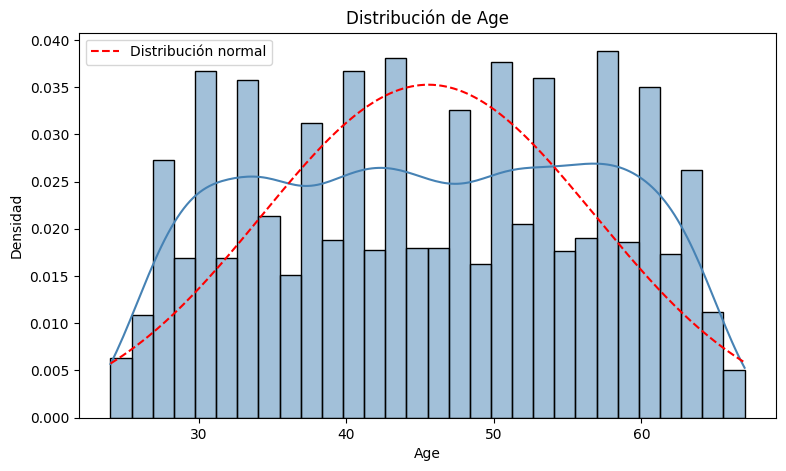

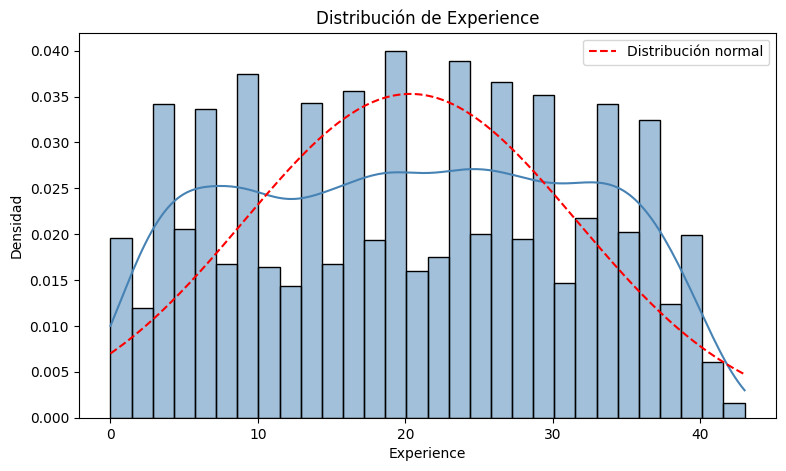

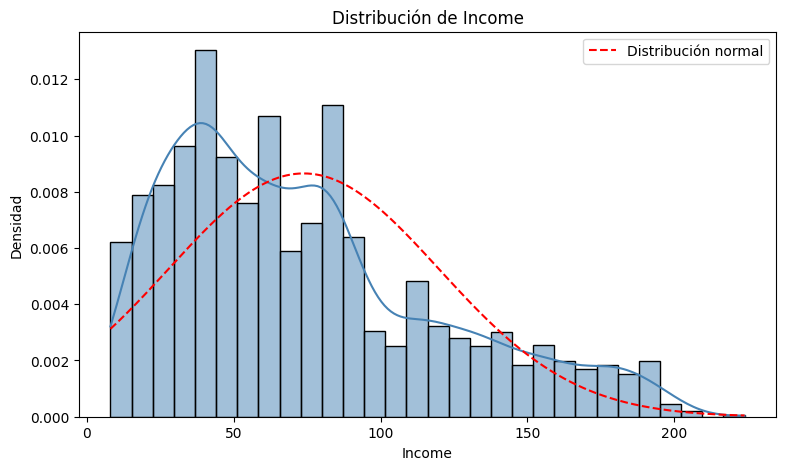

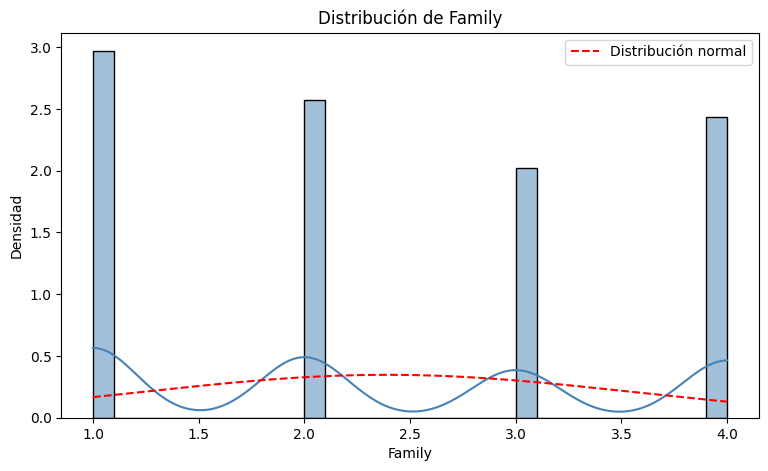

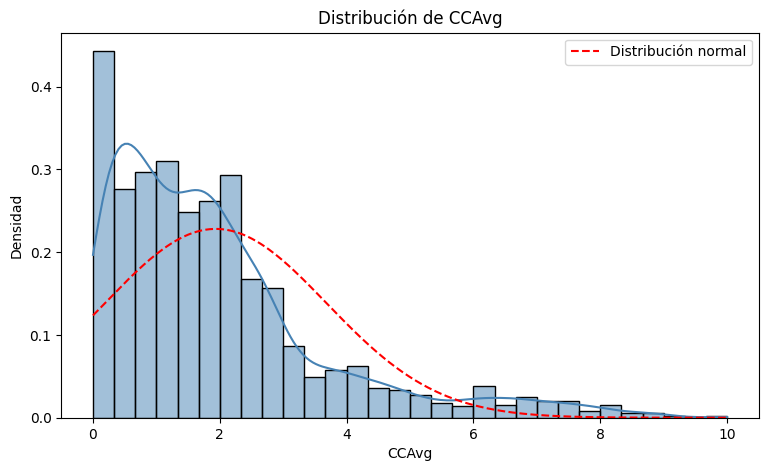

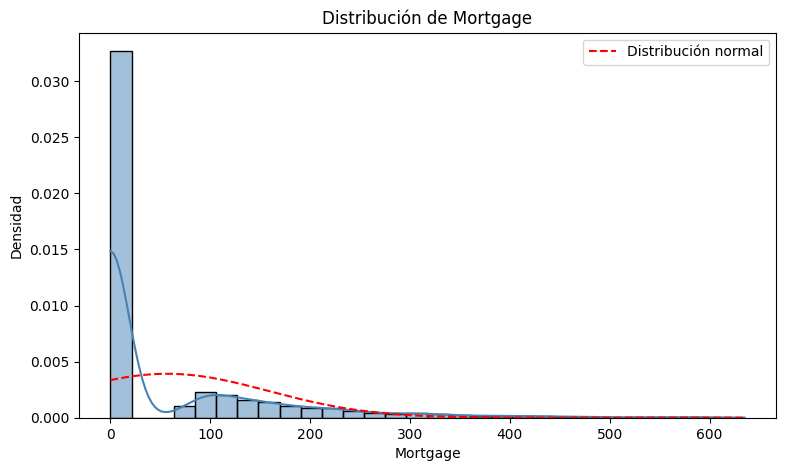

In [59]:
from scipy.stats import norm

for col in num_cols:
    datos = loan_df[col].dropna()

    plt.figure(figsize=(9, 5))

    sns.histplot(
        datos,
        bins=30,
        kde=True,
        stat="density",
        color="steelblue"
    )

    x = np.linspace(datos.min(), datos.max(), 300)

    normal = norm.pdf(
        x,
        loc=datos.mean(),
        scale=datos.std()
    )

    plt.plot(
        x,
        normal,
        color="red",
        linestyle="--",
        label="Distribución normal"
    )

    plt.title(f"Distribución de {col}")
    plt.xlabel(col)
    plt.ylabel("Densidad")
    plt.legend()
    plt.show()

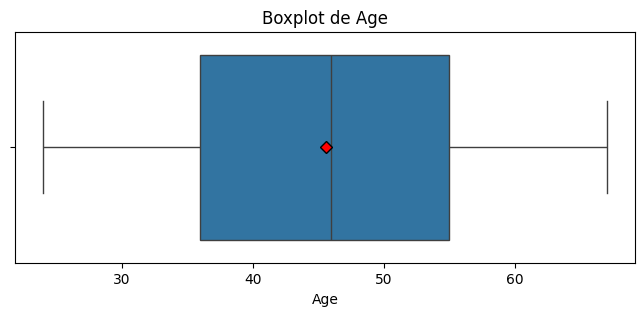

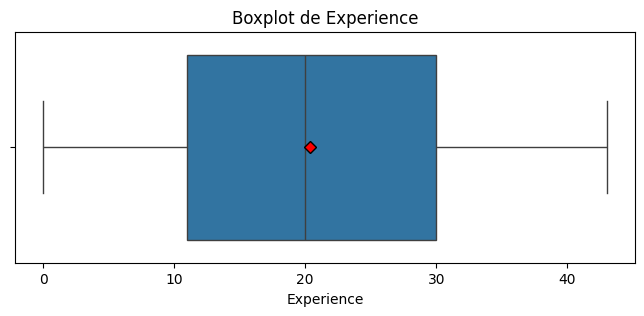

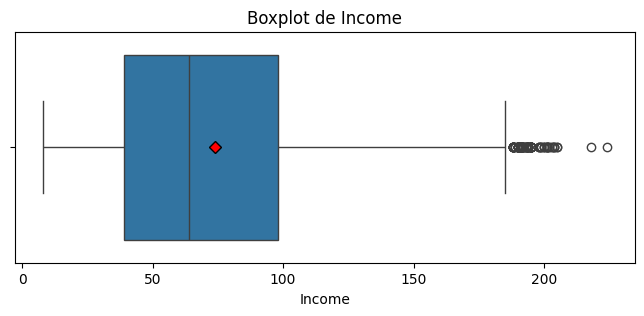

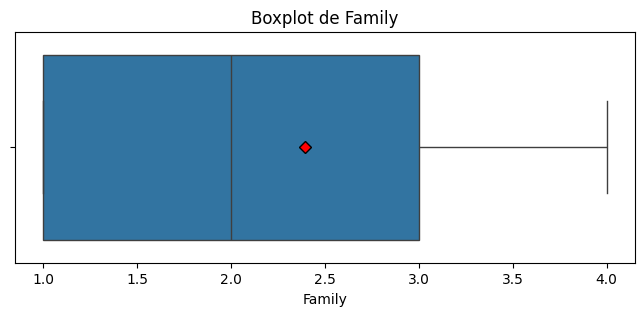

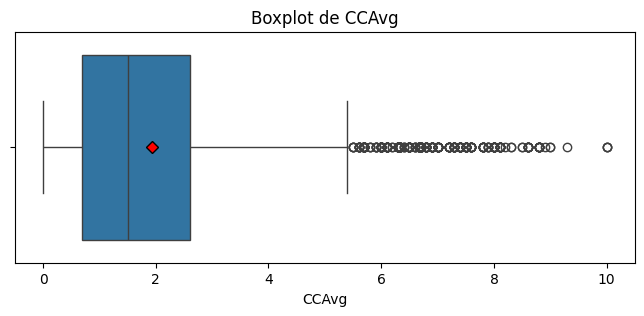

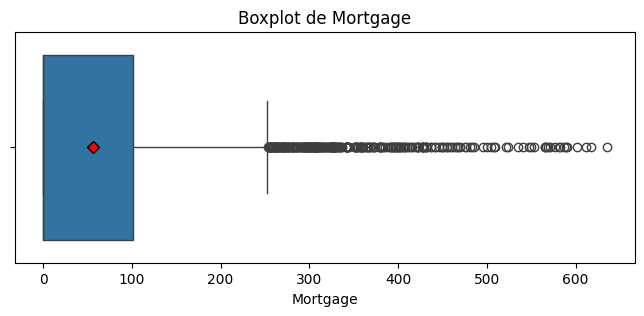

In [60]:
# Gráfico de boxplot incluyendo la media

for col in num_cols:
    plt.figure(figsize=(8, 3))

    sns.boxplot(
        x=loan_df[col],
        showmeans=True,
        meanprops={
            "marker": "D",
            "markerfacecolor": "red",
            "markeredgecolor": "black"
        }
    )

    plt.title(f"Boxplot de {col}")
    plt.show()

In [61]:
# Comparar ambas medidas

comparacion = pd.DataFrame({
    "Media": loan_df[num_cols].mean(),
    "Mediana": loan_df[num_cols].median()
})

comparacion["Diferencia"] = (
    comparacion["Media"] - comparacion["Mediana"]
)

display(comparacion.round(2))

,Media,Mediana,Diferencia
Age,45.56,46.0,-0.44
Experience,20.34,20.0,0.34
Income,73.82,64.0,9.82
Family,2.39,2.0,0.39
CCAvg,1.94,1.5,0.44
Mortgage,56.65,0.0,56.65


Tenemos una asimetría positiva cuando la media supera a la mediana.
Tenemos una asimetría negativa cuando la media es menor a la mediana.

Age - Asimetría negativa
Experience - Asimetría positiva
Income - Asimetría positiva
Family - Asimetría positiva
CCAvg - Asimetría positiva
Mortagege - Asimetría positiva de 0 a 56.65, lo cual confirma que la distribución esta fuertemente concentrada en valores bajos y tiene una cola derecha.

8. Obtén las estadísticas descriptivas de las variables categóricas.
* Genera un gráfico de barras para cada variable. En las de alta cardinalidad, sólo incluye los 10 valores más relevantes.

In [62]:
loan_df[cat_cols].describe().T

,count,unique,top,freq
ZIP Code,4942,468,94720,163
Education,4942,3,1,2079
Personal Loan,4942,2,0,4463
Securities Account,4942,2,0,4427
CD Account,4942,2,0,4641
Online,4942,2,1,2952
CreditCard,4942,2,0,3489


In [63]:
# Frecuencias

for col in cat_cols:
    print(f"\n{col}")
    print(loan_df[col].value_counts(dropna=False))


ZIP Code
ZIP Code
94720    163
94305    123
95616    115
90095     71
93106     56
        ... 
94087      1
91024      1
90068      1
95842      1
94598      1
Name: count, Length: 468, dtype: int64

Education
Education
1    2079
3    1478
2    1385
Name: count, dtype: int64

Personal Loan
Personal Loan
0    4463
1     479
Name: count, dtype: int64

Securities Account
Securities Account
0    4427
1     515
Name: count, dtype: int64

CD Account
CD Account
0    4641
1     301
Name: count, dtype: int64

Online
Online
1    2952
0    1990
Name: count, dtype: int64

CreditCard
CreditCard
0    3489
1    1453
Name: count, dtype: int64


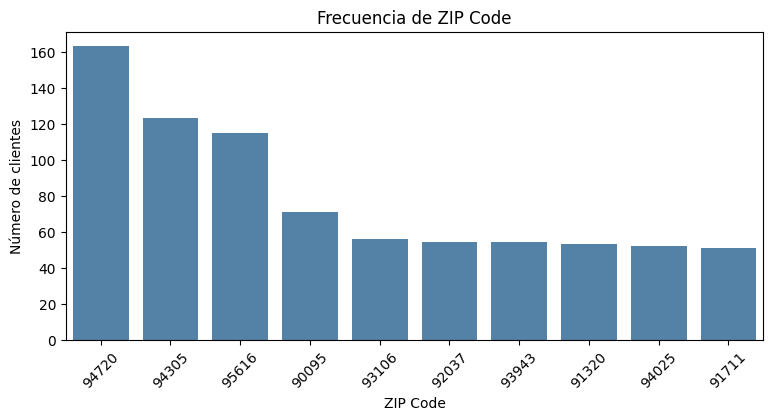

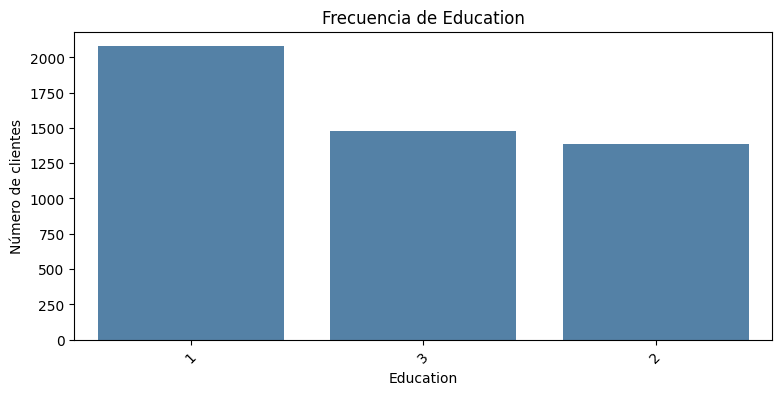

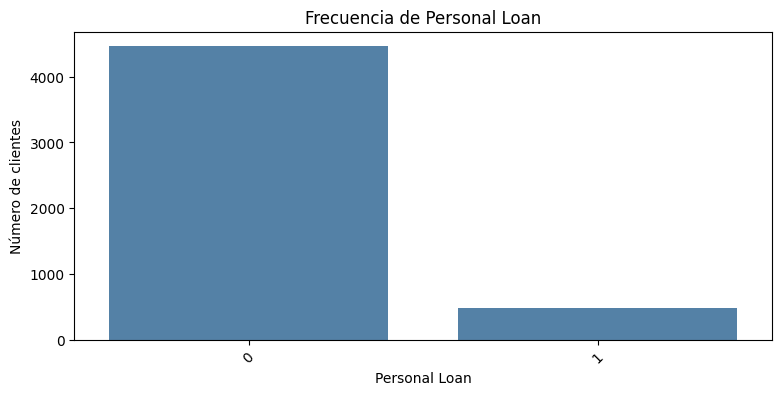

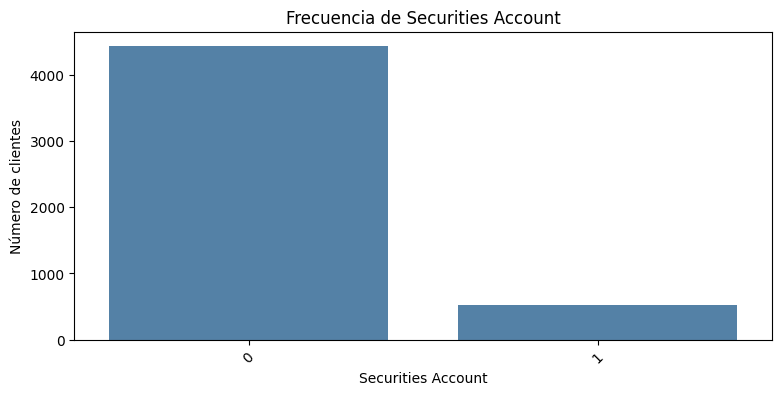

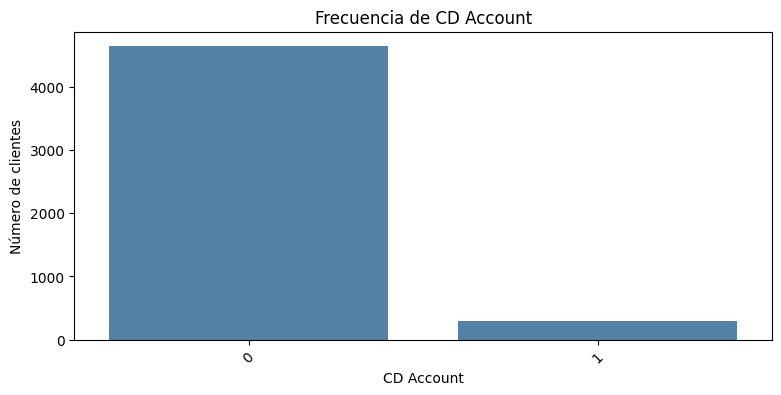

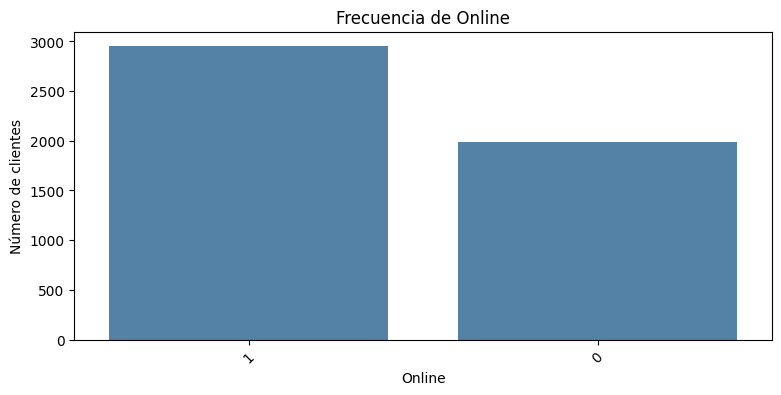

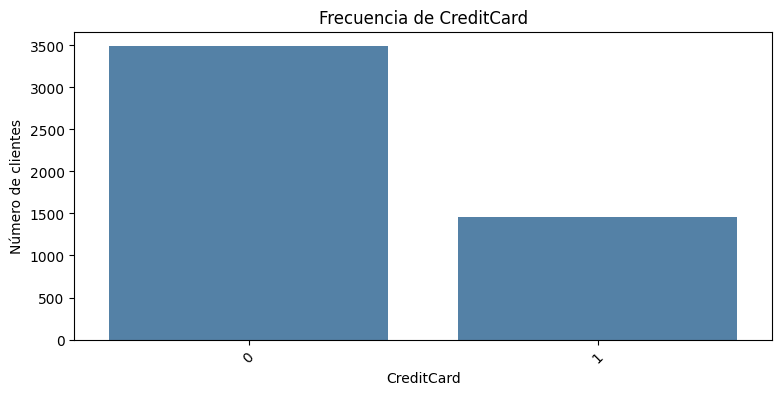

In [64]:
for col in cat_cols:
    frecuencias = (
        loan_df[col]
        .value_counts()
        .head(10)
    )

    plt.figure(figsize=(9, 4))

    sns.barplot(
        x=frecuencias.index.astype(str),
        y=frecuencias.values,
        color="steelblue"
    )

    plt.title(f"Frecuencia de {col}")
    plt.xlabel(col)
    plt.ylabel("Número de clientes")
    plt.xticks(rotation=45)
    plt.show()

# Análisis exploratorio de datos (bivariado)

9. Obtén la matriz de gráficos de dispersión (*scatter matrix*) de todas las variables numéricas.
* Observa las relaciones entre las variables, selecciona un par representativo y describe los patrones o tendencias que sean evidentes.
* Para cuantificar la fuerza y dirección de las relaciones observadas, genera un mapa de calor con los valores de correlación de *Pearson*. ¿El valor numérico obtenido del par seleccionado se corresponde con lo esperado?

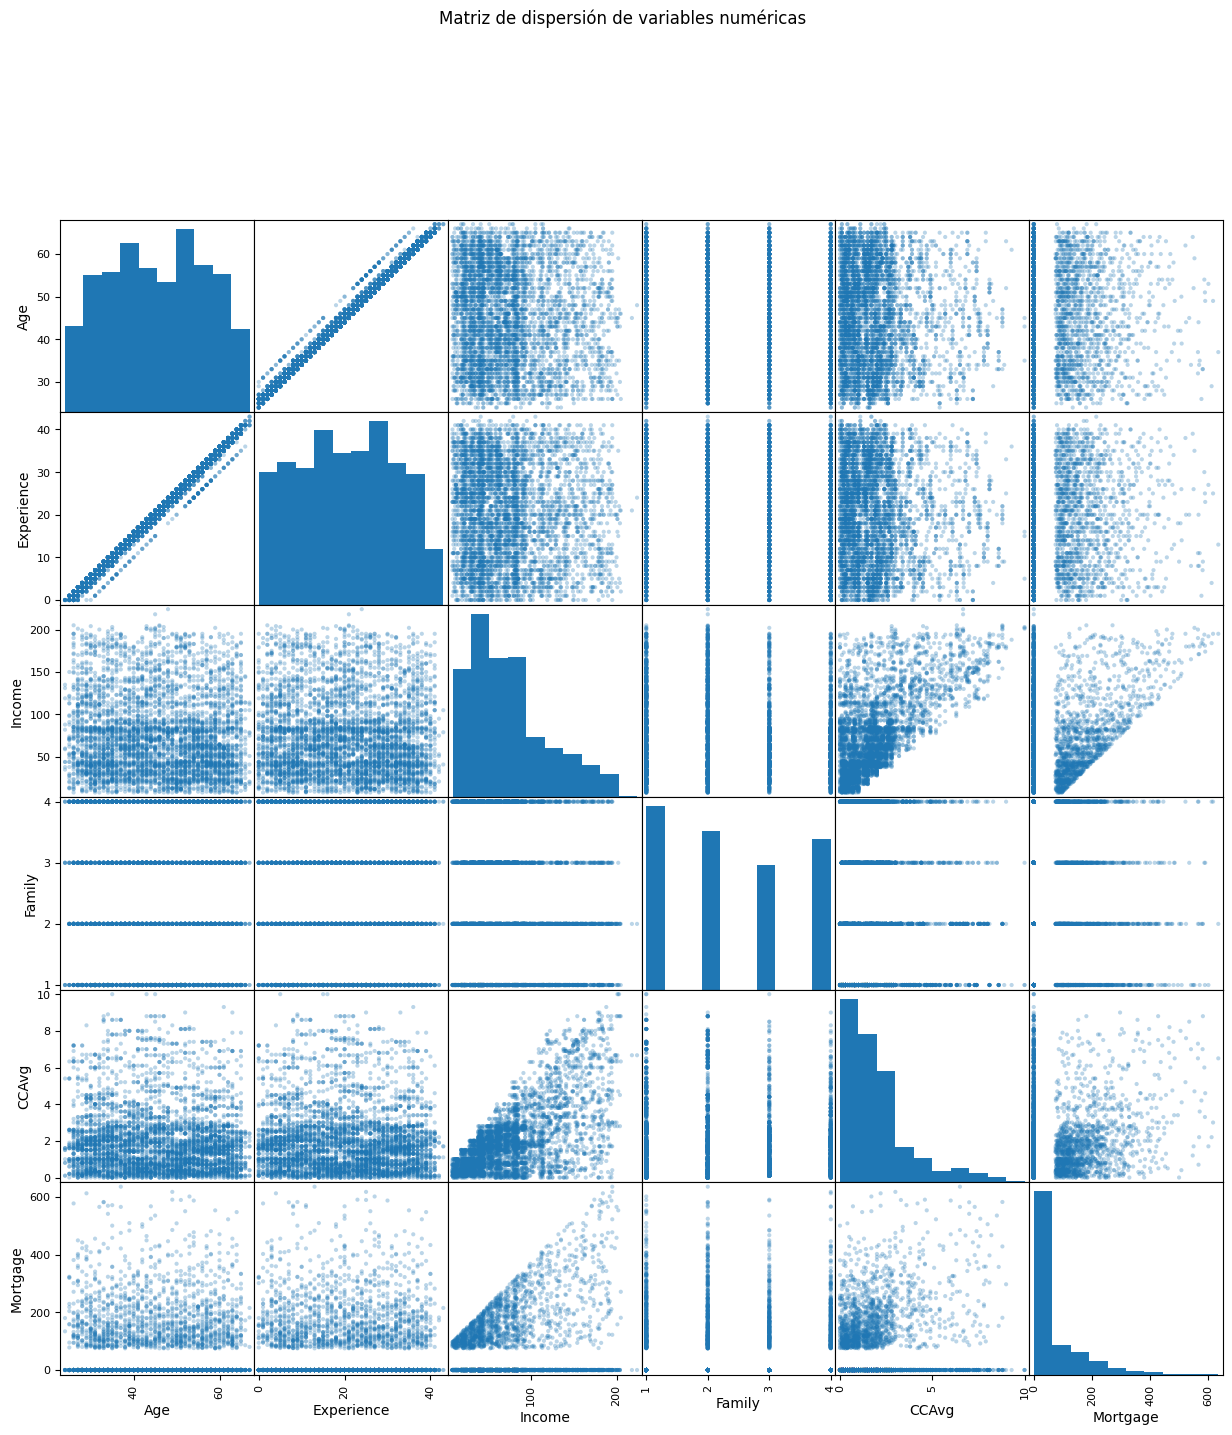

In [65]:
# Creación de la matriz de dispersión

from pandas.plotting import scatter_matrix

scatter_matrix(
    loan_df[num_cols],
    figsize=(15, 15),
    diagonal="hist",
    alpha=0.3
)

plt.suptitle(
    "Matriz de dispersión de variables numéricas",
    y=1.02
)

plt.show()

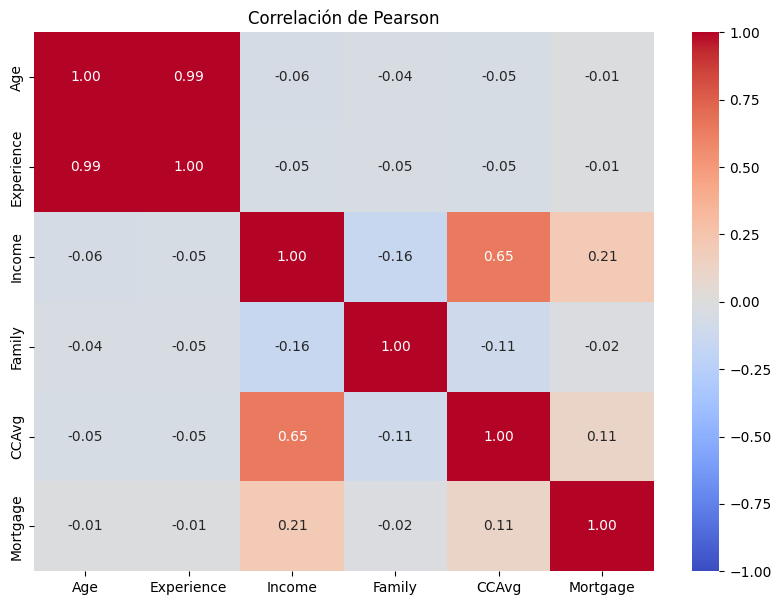

In [66]:
# Mapa de correlaciones

corr_matrix = loan_df[num_cols].corr(
    method="pearson"
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlación de Pearson")
plt.show()

Age & Experience:  

Los clientes de mayor edad tienden a tener más años de experiencia laboral.  Esto coincide con el comportamiento esperado en el gráfico de dispersión y se confirma cuando el coeficiente de Pearson es de 0.994 correlación positiva casi perfecta.


10. Realiza un análisis de todas las variables del dataset con respecto a la variable de salida `Personal Loan`.
* Variables numéricas: Genera box plots para comparar la distribución de cada variable según los valores de `Personal Loan`.
* Variables categóricas (sin considerar `ZIP Code`): Genera gráficos de barras apiladas que muestren la distribución relativa de `Personal Loan` dentro de cada categoría de la variable.
* Para cada grupo de variables (numéricas y categóricas), comenta al menos un hallazgo o patrón relevante observado en los gráficos generados.


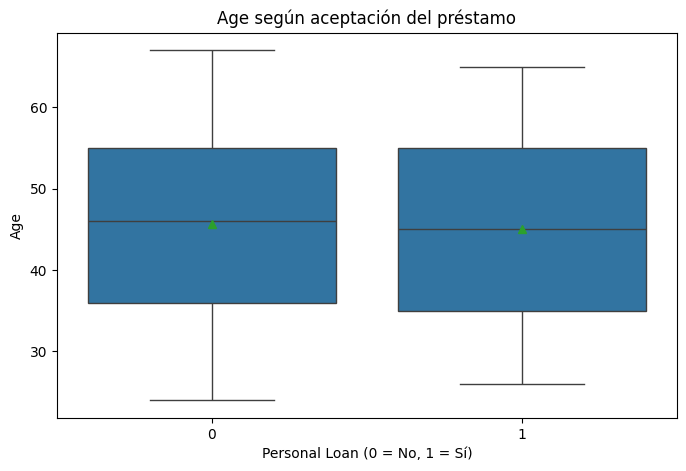

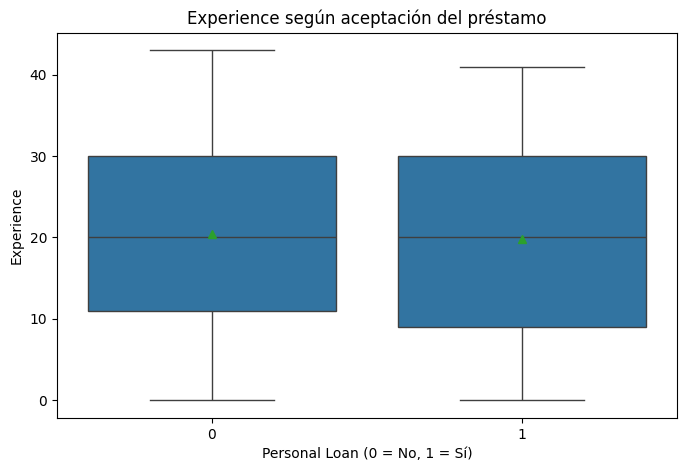

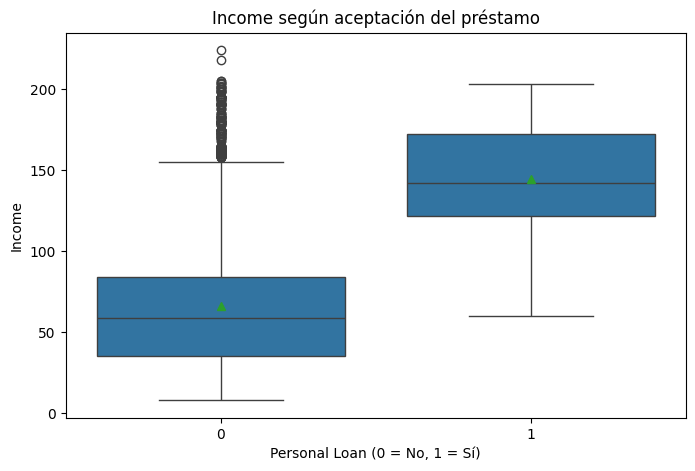

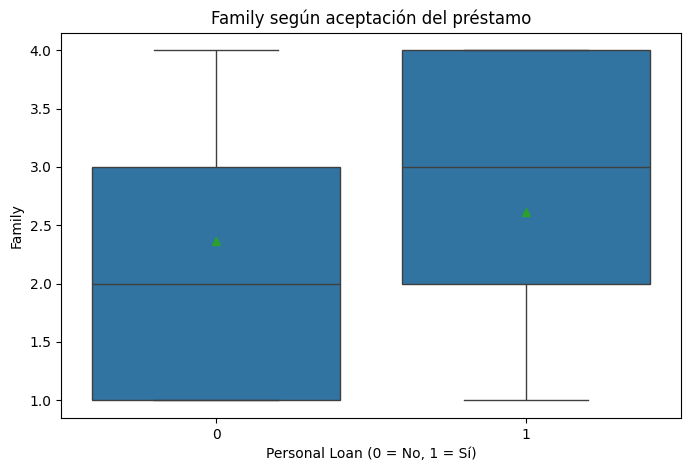

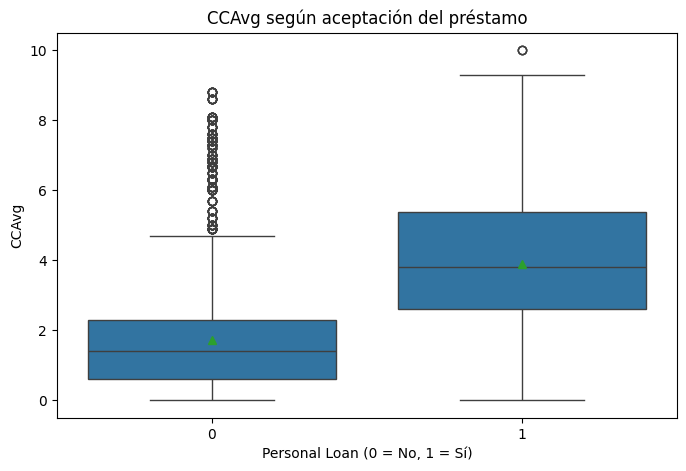

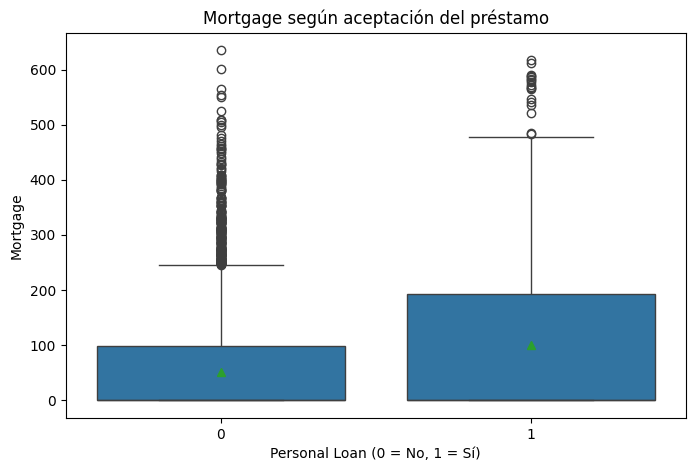

In [67]:
for col in num_cols:
    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=loan_df,
        x="Personal Loan",
        y=col,
        showmeans=True
    )

    plt.title(f"{col} según aceptación del préstamo")
    plt.xlabel("Personal Loan (0 = No, 1 = Sí)")
    plt.ylabel(col)
    plt.show()

In [68]:
loan_df.groupby(
    "Personal Loan",
    observed=True
)[num_cols].median()

,Age,Experience,Income,Family,CCAvg,Mortgage
Personal Loan,,,,,,
0,46.0,20.0,59.0,2.0,1.4,0.0
1,45.0,20.0,142.0,3.0,3.8,0.0


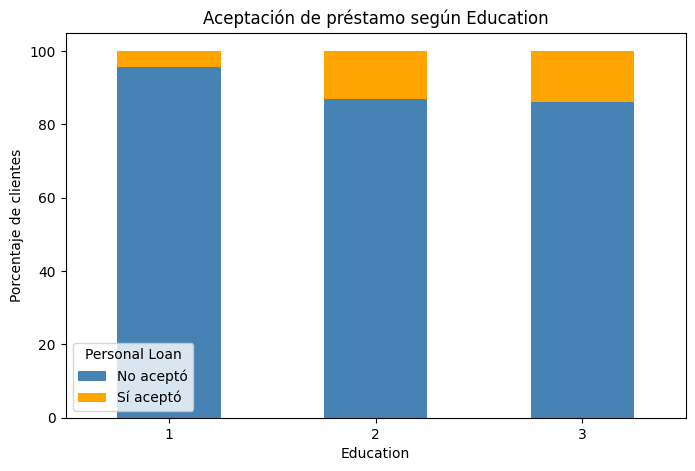

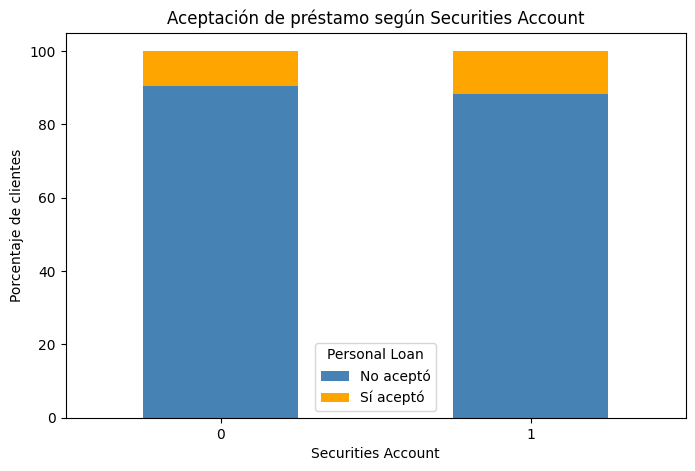

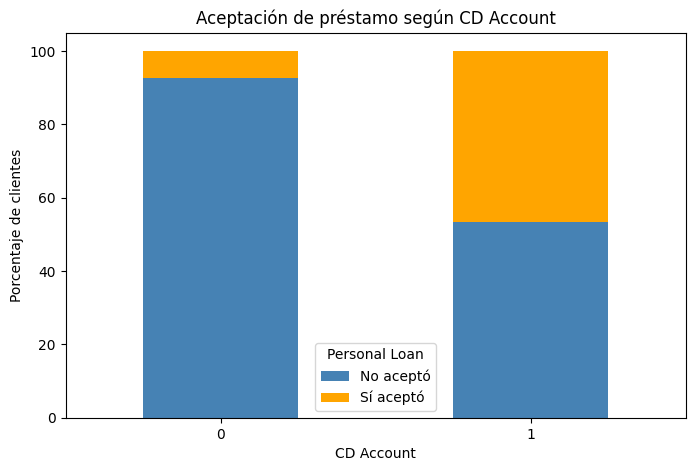

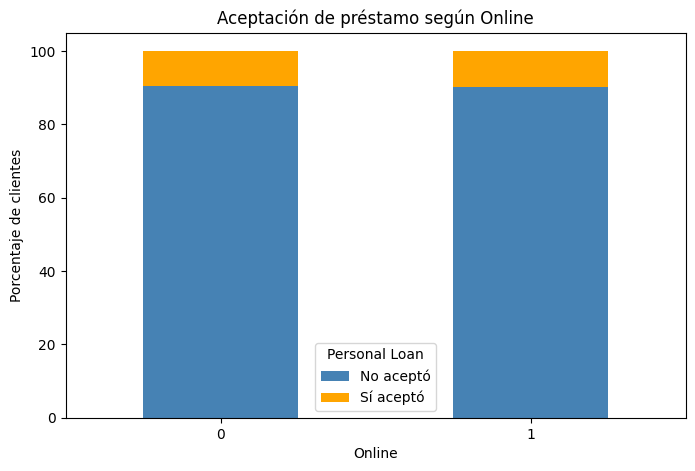

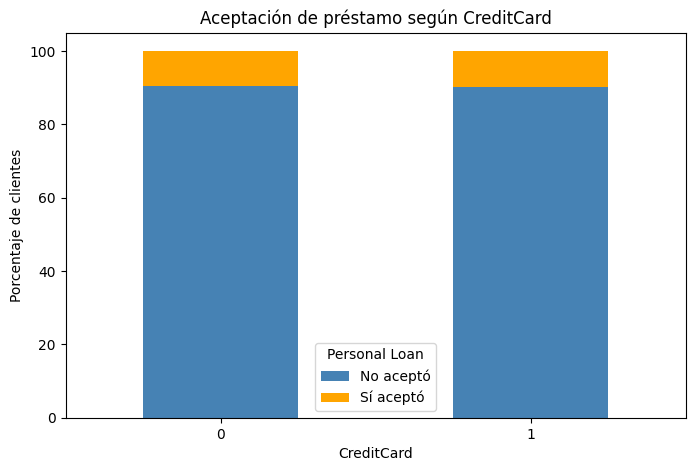

In [69]:
# Excluyendo ZIP Code por alta cardinalidad y Personal Loan ya que se considera variable de salida

cat_predictors = [
    col for col in cat_cols
    if col not in ["ZIP Code", "Personal Loan"]
]

for col in cat_predictors:

    tabla = pd.crosstab(
        loan_df[col],
        loan_df["Personal Loan"],
        normalize="index"
    ) * 100

    tabla.plot(
        kind="bar",
        stacked=True,
        figsize=(8, 5),
        color=["steelblue", "orange"]
    )

    plt.title(f"Aceptación de préstamo según {col}")
    plt.xlabel(col)
    plt.ylabel("Porcentaje de clientes")
    plt.legend(
        title="Personal Loan",
        labels=["No aceptó", "Sí aceptó"]
    )
    plt.xticks(rotation=0)
    plt.show()

Hallazgos

Income:  Los clientes que aceptaron préstamos presentan una mediana de ingresos de 142 mil dólares anuales, comparado con 59 mil dólares de quienes no aceptaron.  La diferencia es considerable.

CCAvg:  Los clientes que aceptaron préstamos también estan presentando gastos mensuales más altos con tarjeta de crédito.

Age y Experience:  Las medianas son muy similares entre ambos grupos, por lo que estas varialbes no presentan una separación tan evidente.

Observamos también que los clientes de los niveles educativos Universitario y Posgrado presentan una mayor proporción de aceptación de prestamos que los de nivel Graduado.

---

**Declaración de uso de IA**

*   OpenAI. (2026). *ChatGPT (basado en GPT-6)*, utilizado para consultar sintaxis de funciones e identificación de inconsistencias en el conjunto de datos. https://chat.openai.com/

---